In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from datetime import timedelta
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score



In [3]:
df = pd.read_csv("retail.csv")
print(df.columns.tolist())


['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [4]:
df = pd.read_csv("retail.csv")

df.columns = df.columns.str.strip()

df = df.rename(columns={
    "Customer ID": "customer_uid",
    "Invoice": "order_uid",
    "InvoiceDate": "order_timestamp",
    "StockCode": "product_sku",
    "Description": "product_name",
    "Quantity": "quantity",
    "Price": "unit_price",
    "Country": "market_country"
})

df = df.dropna(subset=["customer_uid"])
df["customer_uid"] = df["customer_uid"].astype(int)

df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])

df = df[(df["quantity"] > 0) & (df["unit_price"] > 0)]
df["order_value"] = df["quantity"] * df["unit_price"]

df.head()


,order_uid,product_sku,product_name,quantity,order_timestamp,unit_price,customer_uid,market_country,order_value
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [5]:
reference_date = df["order_timestamp"].max() + timedelta(days=1)

rfm = df.groupby("customer_uid").agg({
    "order_timestamp": lambda x: (reference_date - x.max()).days,
    "order_uid": "nunique",
    "order_value": "sum"
}).reset_index()

rfm.columns = ["customer_uid", "recency", "frequency", "monetary"]
rfm.head()


,customer_uid,recency,frequency,monetary
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


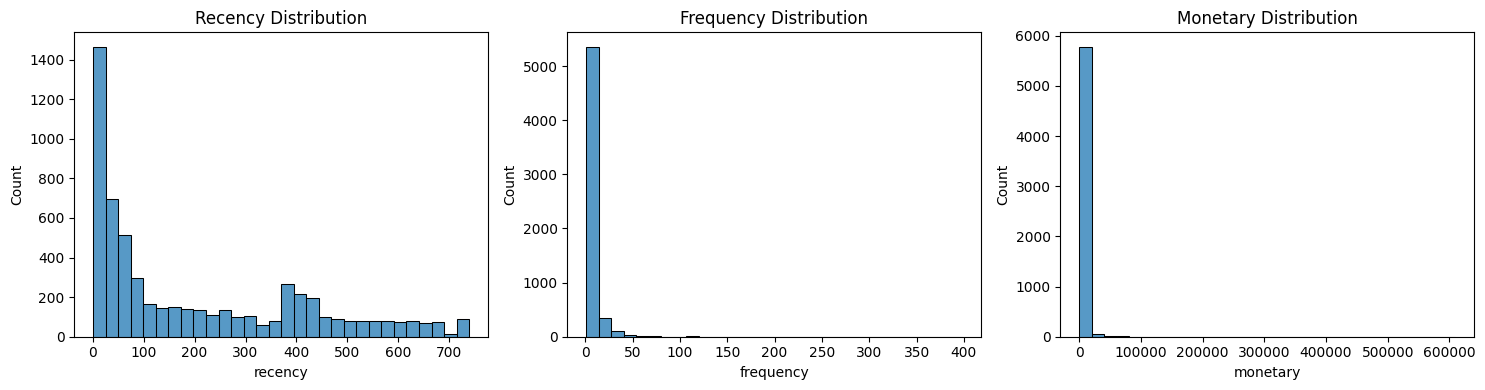

In [6]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm["recency"], bins=30)
plt.title("Recency Distribution")

plt.subplot(1, 3, 2)
sns.histplot(rfm["frequency"], bins=30)
plt.title("Frequency Distribution")

plt.subplot(1, 3, 3)
sns.histplot(rfm["monetary"], bins=30)
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()


In [7]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[["recency", "frequency", "monetary"]])


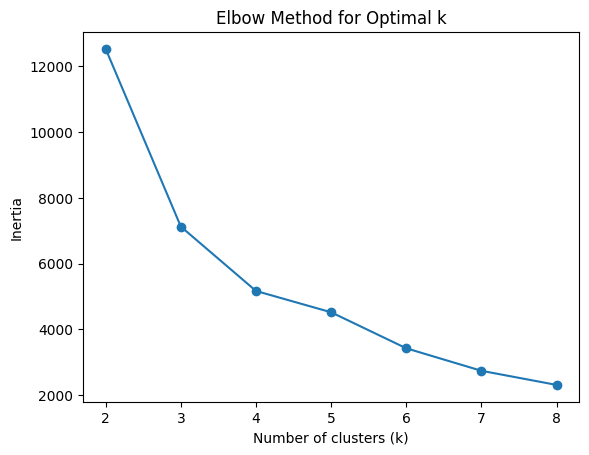

In [8]:
inertia = []
K = range(2, 9)

for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

plt.plot(K, inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()


In [9]:
kmeans = KMeans(n_clusters=4, random_state=42)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

silhouette_score(rfm_scaled, rfm["cluster"])


np.float64(0.5905244621382488)

In [10]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

rfm["pca_1"] = rfm_pca[:, 0]
rfm["pca_2"] = rfm_pca[:, 1]


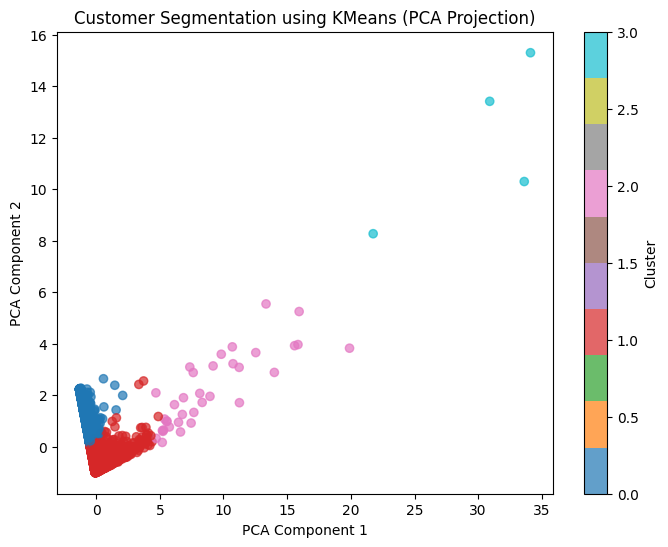

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(
    rfm["pca_1"],
    rfm["pca_2"],
    c=rfm["cluster"],
    cmap="tab10",
    alpha=0.7
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Customer Segmentation using KMeans (PCA Projection)")
plt.colorbar(label="Cluster")
plt.show()


In [12]:
cluster_profile = rfm.groupby("cluster").agg({
    "recency": "mean",
    "frequency": "mean",
    "monetary": "mean",
    "customer_uid": "count"
}).rename(columns={"customer_uid": "num_customers"})

cluster_profile


,recency,frequency,monetary,num_customers
cluster,,,,
0,463.032032,2.212212,765.244446,1998
1,67.005728,7.307732,3009.402451,3841
2,25.942857,103.714286,83086.079771,35
3,3.500000,212.500000,436835.792500,4


C:\Users\anith\AppData\Local\Temp\ipykernel_24856\322893430.py:8: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


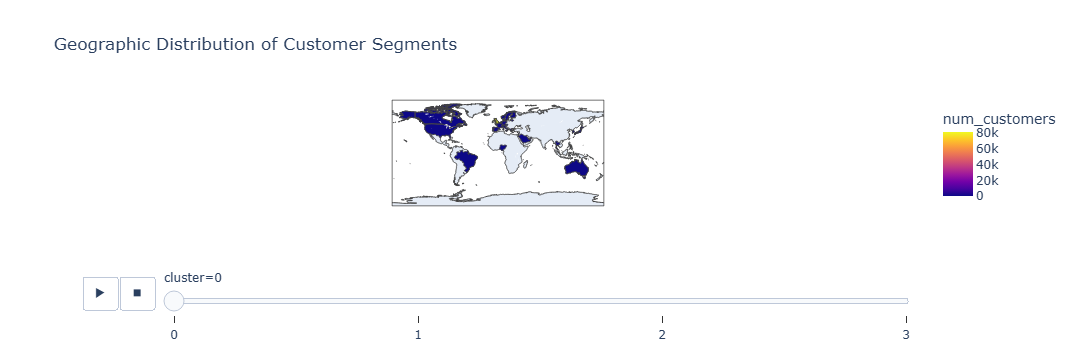

In [13]:
country_cluster = (
    df.merge(rfm[["customer_uid", "cluster"]], on="customer_uid")
      .groupby(["market_country", "cluster"])
      .size()
      .reset_index(name="num_customers")
)

fig = px.choropleth(
    country_cluster,
    locations="market_country",
    locationmode="country names",
    color="num_customers",
    animation_frame="cluster",
    title="Geographic Distribution of Customer Segments"
)

fig.show()


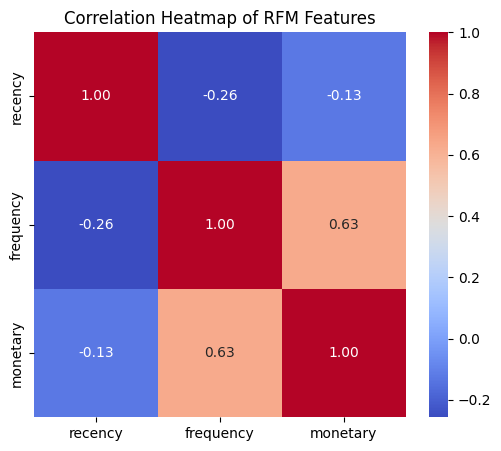

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    rfm[["recency", "frequency", "monetary"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of RFM Features")
plt.show()



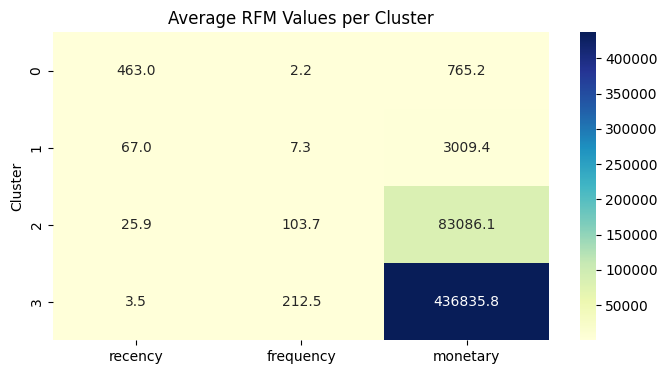

In [15]:
cluster_means = rfm.groupby("cluster")[["recency", "frequency", "monetary"]].mean()

plt.figure(figsize=(8, 4))
sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)
plt.title("Average RFM Values per Cluster")
plt.ylabel("Cluster")
plt.show()


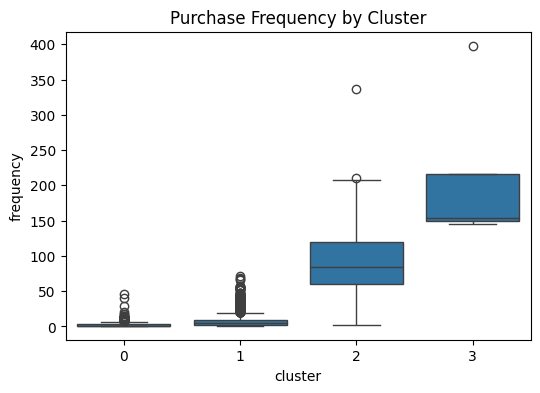

In [16]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="cluster", y="frequency", data=rfm)
plt.title("Purchase Frequency by Cluster")
plt.show()


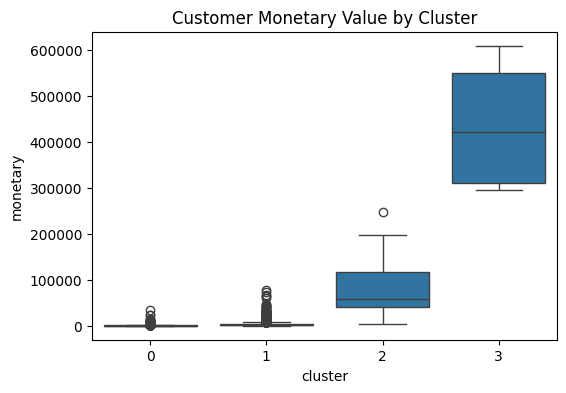

In [17]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="cluster", y="monetary", data=rfm)
plt.title("Customer Monetary Value by Cluster")
plt.show()


In [18]:
rfm["loyal_flag"] = (
    (rfm["recency"] <= rfm["recency"].quantile(0.25)) &
    (rfm["frequency"] >= rfm["frequency"].quantile(0.75)) &
    (rfm["monetary"] >= rfm["monetary"].quantile(0.75))
)

rfm["loyal_flag"].value_counts()


loyal_flag
False    5204
True      674
Name: count, dtype: int64

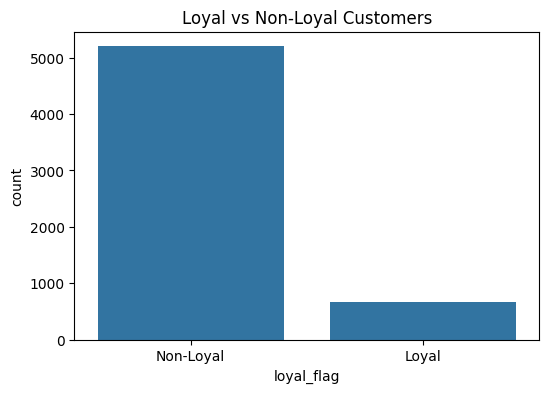

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(x="loyal_flag", data=rfm)
plt.title("Loyal vs Non-Loyal Customers")
plt.xticks([0, 1], ["Non-Loyal", "Loyal"])
plt.show()


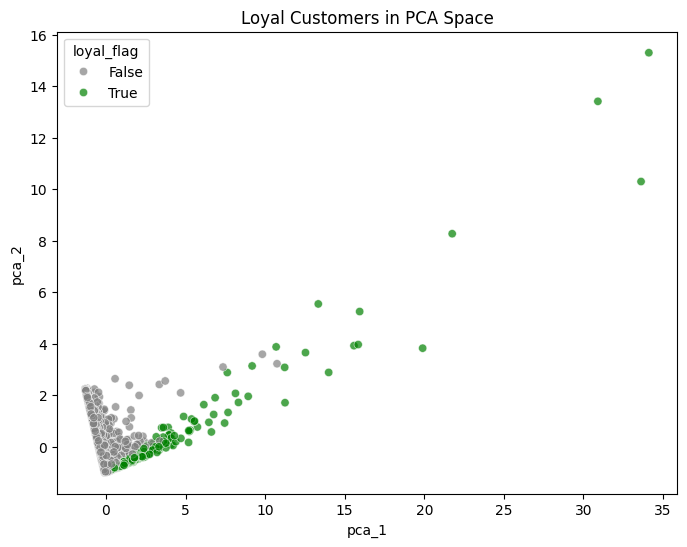

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="pca_1",
    y="pca_2",
    hue="loyal_flag",
    data=rfm,
    palette={True: "green", False: "gray"},
    alpha=0.7
)
plt.title("Loyal Customers in PCA Space")
plt.show()


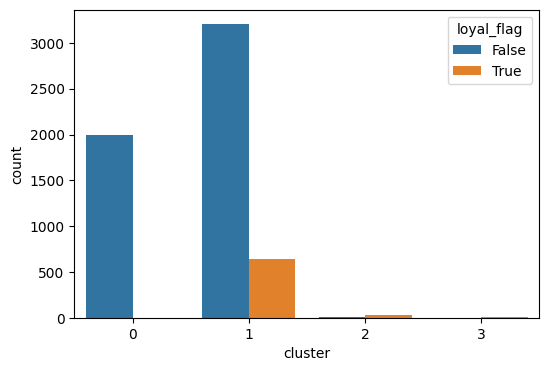

loyal_flag,False,True
cluster,,
0,1.000000,0.000000
1,0.833637,0.166363
2,0.114286,0.885714
3,0.000000,1.000000


In [22]:
loyal_customers = rfm[rfm["loyal_flag"] == True]

top_loyal = loyal_customers.sort_values(by="monetary", ascending=False)

loyal_ids = loyal_customers["customer_uid"]

loyal_transactions = df[df["customer_uid"].isin(loyal_ids)]

top_products = (
    loyal_transactions.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

cluster_loyal_counts = pd.crosstab(rfm["cluster"], rfm["loyal_flag"])

cluster_loyal_percent = pd.crosstab(rfm["cluster"], rfm["loyal_flag"], normalize="index")

plt.figure(figsize=(6,4))
sns.countplot(x="cluster", hue="loyal_flag", data=rfm)
plt.show()

loyal_customers.head()
top_loyal.head(10)
top_products
cluster_loyal_counts
cluster_loyal_percent


In [24]:
def assign_segment(row):
    if row["recency"] <= rfm["recency"].quantile(0.25) and \
       row["frequency"] >= rfm["frequency"].quantile(0.75) and \
       row["monetary"] >= rfm["monetary"].quantile(0.75):
        return "VIP Loyal"

    elif row["recency"] > rfm["recency"].quantile(0.75) and \
         row["frequency"] <= rfm["frequency"].quantile(0.25):
        return "At Risk"

    elif row["frequency"] >= rfm["frequency"].median():
        return "Regular"

    else:
        return "Occasional"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

rfm["segment"].value_counts()


segment
Regular       2637
Occasional    1720
At Risk        847
VIP Loyal      674
Name: count, dtype: int64

In [25]:
vip_customers = rfm[rfm["segment"] == "VIP Loyal"]

vip_customers.to_csv("vip_customers.csv", index=False)

vip_customers.head()


,customer_uid,recency,frequency,monetary,cluster,pca_1,pca_2,loyal_flag,segment
1,12347,2,8,5633.32,1,0.536672,-0.798288,True,VIP Loyal
16,12362,3,11,5356.23,1,0.679517,-0.769598,True,VIP Loyal
34,12380,22,11,9676.30,1,0.836973,-0.580595,True,VIP Loyal
41,12388,16,8,3901.11,1,0.437438,-0.778673,True,VIP Loyal
48,12395,19,15,5067.27,1,0.849010,-0.664663,True,VIP Loyal


In [26]:
vip_ids = vip_customers["customer_uid"]

vip_transactions = df[df["customer_uid"].isin(vip_ids)]

top_vip_products = (
    vip_transactions.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_vip_products


product_name
ASSORTED COLOUR BIRD ORNAMENT         53253
WHITE HANGING HEART T-LIGHT HOLDER    53213
WORLD WAR 2 GLIDERS ASSTD DESIGNS     52501
BROCADE RING PURSE                    51323
JUMBO BAG RED RETROSPOT               50278
SMALL POPCORN HOLDER                  31961
PACK OF 60 PINK PAISLEY CAKE CASES    29758
PACK OF 72 RETROSPOT CAKE CASES       25925
PACK OF 72 RETRO SPOT CAKE CASES      25873
MINI PAINT SET VINTAGE                25827
Name: quantity, dtype: int64

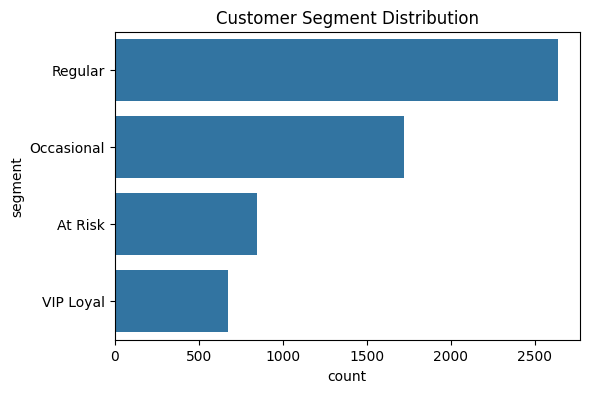

In [27]:
plt.figure(figsize=(6,4))
sns.countplot(y="segment", data=rfm, order=rfm["segment"].value_counts().index)
plt.title("Customer Segment Distribution")
plt.show()


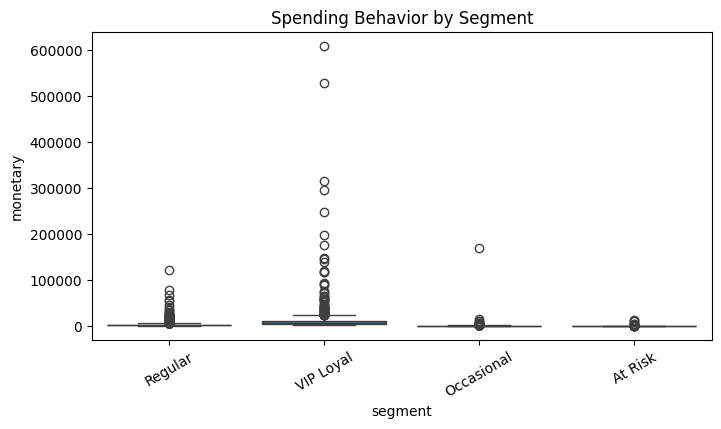

In [28]:
plt.figure(figsize=(8,4))
sns.boxplot(x="segment", y="monetary", data=rfm)
plt.xticks(rotation=30)
plt.title("Spending Behavior by Segment")
plt.show()


In [29]:
rfm.to_csv("rfm_output.csv", index=False)
